# 13 — Robustness Lintas Seed

Seed 42 adalah hasil utama. Seed tambahan (`SEEDS_EXTRA`) **tidak boleh** dipakai untuk memilih model setelah melihat uji; semuanya hanya mengukur seberapa besar variasi inisialisasi mempengaruhi MAE.

- Model: `MODELS_MULTISEED` (DPformer, GRU, GRU-Attn, LSTM-Attn, DLinear, NLinear); DPformer memakai lr/wd hasil MOSSA run utama, model lain default Table 3 jurnal (1e-3 / 1e-4).
- Hasil per run disimpan di `results/seeds/<setup>_<model>_h<h>_s<seed>.json` (+ `_pred.csv`); run yang valid dilewati, jadi aman dihentikan dan dilanjutkan.
- Perkiraan waktu FULL pada CPU 2 thread: sekitar 2–3 jam (240 run).

In [1]:
import sys, os, json, time, warnings

# Batasi thread CPU supaya laptop tetap responsif selama training berjam-jam.
# Default 2 thread. Ubah lewat env TA_THREADS. Harus di kernel BARU (sebelum numpy/tensorflow aktif).
N_THREADS = int(os.environ.get('TA_THREADS', '2'))
for _v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(_v, str(N_THREADS))

sys.path.insert(0, os.path.join('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display
try:
    tf.config.threading.set_intra_op_parallelism_threads(N_THREADS)
    tf.config.threading.set_inter_op_parallelism_threads(1)
except RuntimeError:
    print('[PERHATIAN] TensorFlow sudah aktif di kernel ini, batas thread tidak berlaku. Restart kernel.')

from src.config import (OUT, HORIZONS, SETUPS, ML_MODELS, DL_MODELS, ALL_MODELS, LANG, PROTOCOL, ML_REV, QUICK,
                        SEQ_LEN, EPOCHS, PATIENCE, BASE_LR, BASE_WD, DL_BATCH, DL_UNITS)
from src import analysis as A, plots as P, stats as S, runners as R
from src.pipeline import SEED, load_mossa, free_memory
from src.runners import load_data, data_fingerprint

P.set_lang(LANG)
RES = os.path.join(OUT, 'results')
RUNS = os.path.join(RES, 'runs')
FIGS = os.path.join(OUT, 'figures')
MODEL_DIR = os.path.join(RES, 'models')
for _d in (RES, RUNS, FIGS, MODEL_DIR):
    os.makedirs(_d, exist_ok=True)

df, p, exo = load_data('..')
DATA_HASH = data_fingerprint(df)
print(f'Data: {len(p)} hari kerja, {p.index[0].date()} s.d. {p.index[-1].date()} | sidik jari {DATA_HASH}'
      + (' | MODE QUICK (hasil hanya uji kelancaran)' if QUICK else ''))


def simpan(fig, nama):
    P.save_fig(fig, nama, FIGS)
    plt.show()
    plt.close(fig)

import json
from src.config import SEEDS_EXTRA, MODELS_MULTISEED
from src.pipeline import run_is_current
SEED_DIR = os.path.join(RES, 'seeds')
os.makedirs(SEED_DIR, exist_ok=True)
mossa_all = load_mossa(os.path.join(RES, 'mossa_dpformer.json'))
if mossa_all is None:
    raise RuntimeError('MOSSA DPformer belum tersedia. Jalankan notebook 05 terlebih dahulu.')
print('Seed tambahan:', SEEDS_EXTRA, '| model:', MODELS_MULTISEED)

Data: 4325 hari kerja, 2010-01-05 s.d. 2026-08-03 | sidik jari 7aea8db80d44
Seed tambahan: [43, 44, 45, 46] | model: ['dpformer', 'gru', 'gru_att', 'lstm_att', 'dlinear', 'nlinear']


In [2]:
def lr_wd(setup, model):
    if model == 'dpformer':
        lr, wd, _ = mossa_all[setup]
        return lr, wd
    return BASE_LR, BASE_WD


rows, gagal = [], []
for seed in SEEDS_EXTRA:
    for setup in SETUPS:
        for model in MODELS_MULTISEED:
            for h in HORIZONS:
                jf = os.path.join(SEED_DIR, f'{setup}_{model}_h{h}_s{seed}.json')
                if run_is_current(jf, data_hash=DATA_HASH):          # hasil lama tanpa sidik jari diterima (diverifikasi nb08)
                    with open(jf, encoding='utf-8') as f:
                        rows.append(json.load(f))
                    continue
                lr, wd = lr_wd(setup, model)
                try:
                    res, pred_df, hist, _ = R.run_dl(p, exo if setup == 'multivariat' else None, setup, model, h,
                                                     lr=lr, wd=wd, seed=seed, data_hash=DATA_HASH)
                except Exception as e:                                # noqa: BLE001
                    print(f'GAGAL {setup}/{model}/h{h}/s{seed}: {type(e).__name__}: {e}')
                    gagal.append((setup, model, h, seed))
                    free_memory()
                    continue
                pred_df.to_csv(os.path.join(SEED_DIR, f'{setup}_{model}_h{h}_s{seed}_pred.csv'), index=False)
                with open(jf, 'w', encoding='utf-8') as f:
                    json.dump(res, f)
                rows.append(res)
                print(f'{setup:11s} {model:9s} h={h:2d} seed={seed}  MAE={res["MAE"]:,.0f}  ({res["waktu_detik"]}s)')
assert not gagal, f'Ada run gagal: {gagal}'
print(f'Selesai. Total hasil seed tambahan: {len(rows)} (diharapkan {len(SEEDS_EXTRA) * len(SETUPS) * len(MODELS_MULTISEED) * len(HORIZONS)})')


univariat   dpformer  h= 1 seed=43  MAE=13,235  (45.6s)
univariat   dpformer  h= 5 seed=43  MAE=29,949  (53.3s)
univariat   dpformer  h=10 seed=43  MAE=42,532  (46.0s)
univariat   dpformer  h=20 seed=43  MAE=62,707  (46.1s)
univariat   dpformer  h=30 seed=43  MAE=82,441  (49.7s)
univariat   gru       h= 1 seed=43  MAE=13,302  (42.9s)
univariat   gru       h= 5 seed=43  MAE=30,112  (41.9s)
univariat   gru       h=10 seed=43  MAE=42,564  (42.3s)
univariat   gru       h=20 seed=43  MAE=62,826  (44.3s)
univariat   gru       h=30 seed=43  MAE=83,038  (42.1s)
univariat   gru_att   h= 1 seed=43  MAE=13,261  (26.9s)
univariat   gru_att   h= 5 seed=43  MAE=30,142  (24.8s)
univariat   gru_att   h=10 seed=43  MAE=42,684  (25.8s)
univariat   gru_att   h=20 seed=43  MAE=62,605  (23.5s)
univariat   gru_att   h=30 seed=43  MAE=81,704  (26.8s)
univariat   lstm_att  h= 1 seed=43  MAE=13,259  (13.2s)
univariat   lstm_att  h= 5 seed=43  MAE=30,049  (11.2s)
univariat   lstm_att  h=10 seed=43  MAE=42,653 

## Ringkasan lintas seed (seed 42 = hasil utama ikut dihitung)

In [3]:
d = pd.DataFrame(rows)[['setup', 'model', 'horizon', 'seed', 'MAE', 'RMSE', 'MAPE']]
main = pd.read_csv(os.path.join(RES, 'tabel_hasil_final.csv'))
main = main[main.model.isin(MODELS_MULTISEED) & main.horizon.isin(HORIZONS)][['setup', 'model', 'horizon', 'MAE', 'RMSE', 'MAPE']].assign(seed=SEED)
allseeds = pd.concat([main, d], ignore_index=True)
drb = pd.read_csv(os.path.join(RES, 'drift_benchmark.csv')).set_index('horizon')['MAE']

g = allseeds.groupby(['setup', 'model', 'horizon'])
summary = g.MAE.agg(n_seed='count', MAE_mean='mean', MAE_std='std', MAE_min='min', MAE_max='max').reset_index()
summary['CV_pct'] = 100 * summary.MAE_std / summary.MAE_mean
summary['MAE_seed42'] = [float(main[(main.setup == r.setup) & (main.model == r.model) & (main.horizon == r.horizon)].MAE.iloc[0]) for r in summary.itertuples()]
summary['drift_MAE'] = summary.horizon.map(drb)
summary['pct_vs_drift_rata2'] = 100 * (summary.drift_MAE - summary.MAE_mean) / summary.drift_MAE
summary['n_seed_lebih_baik_dari_drift'] = [int((allseeds[(allseeds.setup == r.setup) & (allseeds.model == r.model) & (allseeds.horizon == r.horizon)].MAE < r.drift_MAE).sum()) for r in summary.itertuples()]
summary.to_csv(os.path.join(RES, 'multiseed_ringkasan.csv'), index=False)
allseeds.to_csv(os.path.join(RES, 'multiseed_semua.csv'), index=False)

print('Variasi MAE antar seed (CV %) per model dan setup, rata-rata atas horizon:')
display(summary.pivot_table(index='model', columns='setup', values='CV_pct', aggfunc='mean').round(2))
print('Rata-rata perbaikan MAE (seed-rata-rata) terhadap Drift, % (positif = lebih baik):')
display(summary.pivot_table(index=['setup', 'model'], columns='horizon', values='pct_vs_drift_rata2').round(2))
print('Jumlah seed (dari 5) dengan MAE < Drift:')
display(summary.pivot_table(index=['setup', 'model'], columns='horizon', values='n_seed_lebih_baik_dari_drift').astype(int))

Variasi MAE antar seed (CV %) per model dan setup, rata-rata atas horizon:


setup,multivariat,univariat
model,,
dlinear,0.27,0.14
dpformer,0.57,0.32
gru,0.76,0.47
gru_att,0.52,0.24
lstm_att,0.58,0.14
nlinear,0.16,0.15


Rata-rata perbaikan MAE (seed-rata-rata) terhadap Drift, % (positif = lebih baik):


horizon                 1     5     10    20    30
setup       model                                 
multivariat dlinear  -2.96 -1.37  1.40  1.37  0.00
            dpformer -0.67 -0.19  0.42 -0.02 -0.53
            gru      -2.53 -1.41  0.80 -1.01  0.25
            gru_att  -0.00  0.67  1.39 -1.55  1.11
            lstm_att -0.05  0.38  0.18  0.62  0.88
            nlinear  -7.07 -5.09 -4.55 -1.01  1.55
univariat   dlinear  -0.98 -0.41 -0.31  0.83  1.09
            dpformer -0.06  0.25  0.33 -0.15 -0.20
            gru      -0.86 -0.68 -0.13  0.16  0.60
            gru_att  -0.13 -0.22  0.11  0.54  1.42
            lstm_att -0.10  0.04  0.07  0.95  1.35
            nlinear  -5.24 -3.67 -4.24 -1.00  1.72

Jumlah seed (dari 5) dengan MAE < Drift:


horizon               1   5   10  20  30
setup       model                       
multivariat dlinear    0   0   5   5   2
            dpformer   0   2   3   2   1
            gru        0   0   5   1   3
            gru_att    2   5   4   0   5
            lstm_att   1   4   4   5   5
            nlinear    0   0   0   0   5
univariat   dlinear    0   0   0   5   5
            dpformer   3   5   5   1   1
            gru        0   0   1   4   4
            gru_att    0   0   4   4   5
            lstm_att   0   4   4   5   5
            nlinear    0   0   0   0   5

rasio < ~2: urutan model-DL tidak dapat dibedakan dari variasi seed.


,setup,horizon,sd_antar_model,sd_antar_seed_rata2,rasio_antar_model_per_antar_seed
0,multivariat,1,356.502,60.168,5.925
1,multivariat,5,634.639,92.262,6.879
2,multivariat,10,961.922,270.406,3.557
3,multivariat,20,705.122,366.247,1.925
4,multivariat,30,643.967,339.122,1.899
5,univariat,1,266.084,32.344,8.227
6,univariat,5,436.760,50.975,8.568
7,univariat,10,747.935,70.717,10.576
8,univariat,20,456.855,184.527,2.476
9,univariat,30,582.204,284.316,2.048


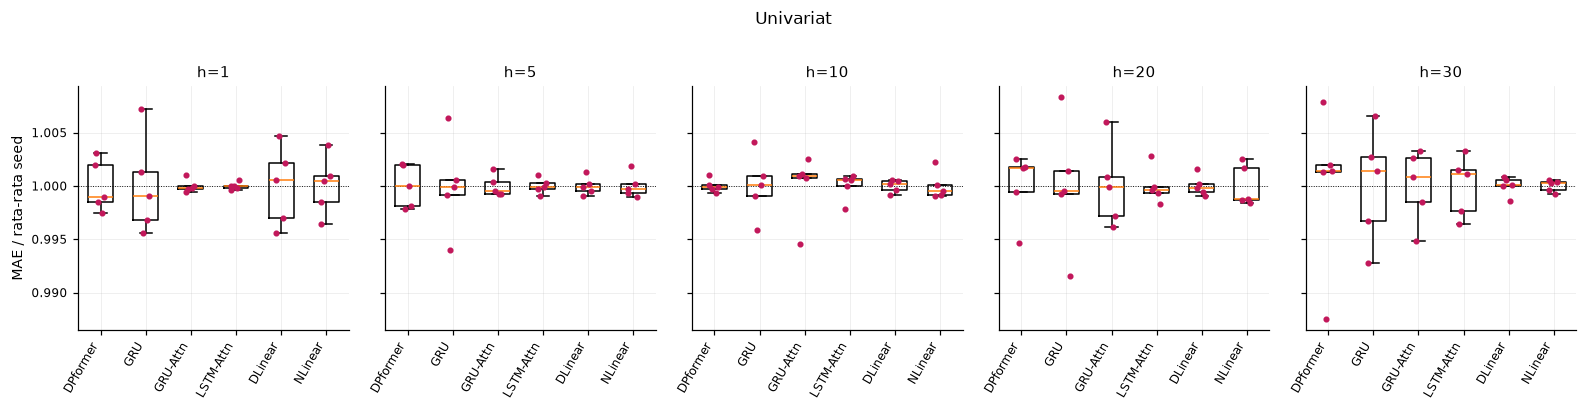

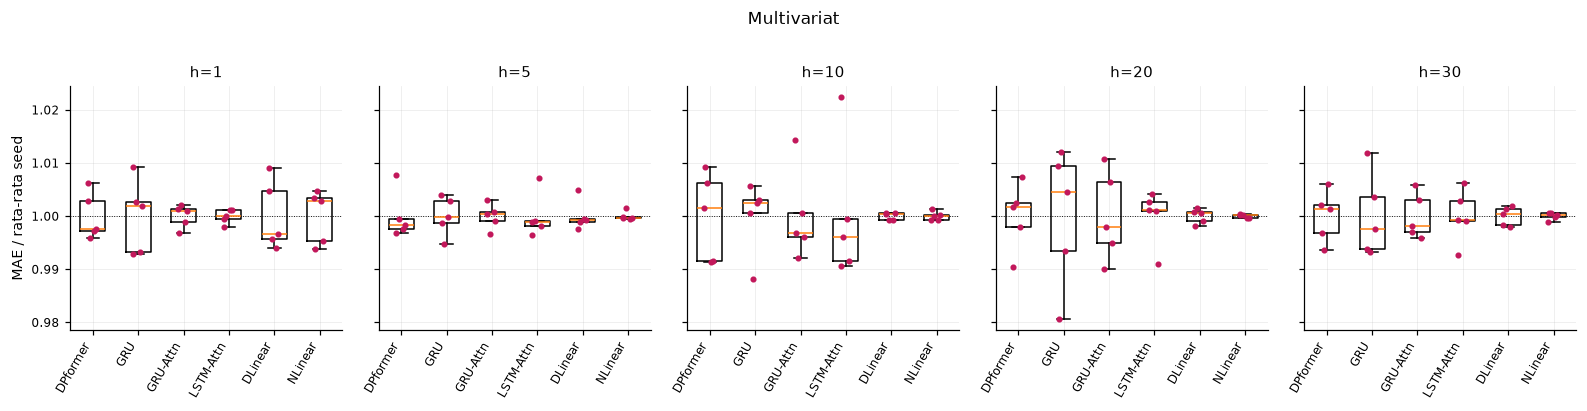

In [4]:
# apakah beda antar-model lebih besar daripada variasi antar-seed?
w = summary.groupby(['setup', 'horizon']).agg(sd_antar_model=('MAE_mean', 'std'), sd_antar_seed_rata2=('MAE_std', 'mean')).reset_index()
w['rasio_antar_model_per_antar_seed'] = w.sd_antar_model / w.sd_antar_seed_rata2
print('rasio < ~2: urutan model-DL tidak dapat dibedakan dari variasi seed.')
display(w.round(3))
for setup in SETUPS:
    fig = P.fig_seed_box(allseeds[allseeds.setup == setup], HORIZONS, MODELS_MULTISEED, setup)
    simpan(fig, f'fig_seed_{setup}')

**Cara membaca.** CV kecil berarti hasil stabil terhadap seed. Selisih MAE antar model/Drift yang **lebih kecil daripada rentang antar-seed** tidak boleh diklaim sebagai keunggulan. Tabel *rasio antar-model / antar-seed* menunjukkan seberapa jauh urutan DL melampaui derau inisialisasi; bila mendekati 1–2, urutan tersebut sebagian besar kebetulan inisialisasi.